# 07 MultiRocket

**Goal:** train MiniRocket on the raw 5 m windows (from 06) and compare it with the random forest, using the same road split and metrics.

**Why MiniRocket:** it is made for time series classification. It looks at the raw signal shape with thousands of small random filters, instead of using features we choose by hand (like std).

In [12]:
""" import sys
print(sys.executable)
!"{sys.executable}" -m pip install sktime numba """

' import sys\nprint(sys.executable)\n!"{sys.executable}" -m pip install sktime numba '

In [13]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

# Checking that sktime is installed, and which version we have.
import sktime
from sktime.transformations.rocket import MultiRocketMultivariate
from sklearn.linear_model import RidgeClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
print("sktime version:", sktime.__version__)

sktime version: 1.3.0


In [14]:
# Loading the raw windows we built in 06.
# Shape: (windows, sensors, time steps) -> this is the shape sktime expects (channels first).
X_raw = np.load("data_features/raw_windows_5m.npy").astype(np.float32)

# For every window: which drive and road it comes from, and whether it is a bump (1) or not (0).
raw_index = pd.read_csv("data_features/raw_windows_index.csv")

print("X_raw shape:", X_raw.shape)
print("raw_index shape:", raw_index.shape)

X_raw shape: (2728, 7, 100)
raw_index shape: (2728, 4)


In [15]:
# The road we test on. The model never sees this road during training.
test_road = "Iisingintie"

# True for windows from the test road, False for all the others.
is_test = (raw_index["road"] == test_road).to_numpy()

# Splitting the signals (X) and the answers (y).
# ~ means "not", so ~is_test = the windows from the other two roads.
X_train = X_raw[~is_test]
X_test = X_raw[is_test]
y_train = raw_index["is_bump"].to_numpy()[~is_test]
y_test = raw_index["is_bump"].to_numpy()[is_test]

print("Train:", X_train.shape, " bump share:", round(y_train.mean(), 2))
print("Test: ", X_test.shape, " bump share:", round(y_test.mean(), 2))

Train: (915, 7, 100)  bump share: 0.19
Test:  (1813, 7, 100)  bump share: 0.19


In [31]:
# ---- Step 1: MultiRocket turns every window into ~50,000 numbers ----
multirocket = MultiRocketMultivariate(
    num_kernels=3000,      # default; gives ~50k features (4 per kernel)
    random_state=541,
)

multirocket.fit(X_train)                       # training windows only
X_train_feat = multirocket.transform(X_train)
X_test_feat = multirocket.transform(X_test)

print("Before MultiRocket:", X_train.shape)
print("After MultiRocket: ", X_train_feat.shape)

# ---- Step 2: scale (unchanged) ----
scaler = StandardScaler(with_mean=False)
X_train_feat = scaler.fit_transform(X_train_feat)
X_test_feat = scaler.transform(X_test_feat)

# ---- Step 3: classifier (unchanged) ----
classifier = RidgeClassifierCV(alphas=np.logspace(-3, 3, 10), class_weight="balanced")
classifier.fit(X_train_feat, y_train)

y_pred = classifier.predict(X_test_feat)
y_score = classifier.decision_function(X_test_feat)

Before MultiRocket: (2427, 7, 100)
After MultiRocket:  (2427, 23520)


In [32]:
# ROC-AUC: how well the scores separate bumps from non-bumps (0.5 = guessing, 1.0 = perfect).
print("ROC-AUC:", round(roc_auc_score(y_test, y_score), 2))

# Precision, recall and f1 for both classes. The "1" row is the bump class.
print(classification_report(y_test, y_pred, zero_division=0))

ROC-AUC: 0.68
              precision    recall  f1-score   support

           0       0.56      0.96      0.71       161
           1       0.75      0.13      0.22       140

    accuracy                           0.57       301
   macro avg       0.65      0.55      0.46       301
weighted avg       0.65      0.57      0.48       301



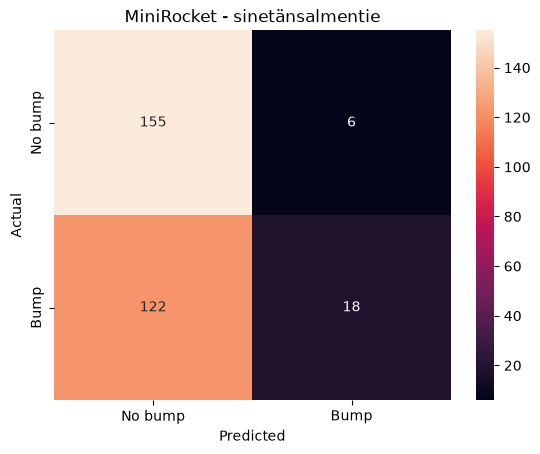

In [33]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["No bump", "Bump"],
    yticklabels=["No bump", "Bump"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MiniRocket - " + test_road)
plt.show()

### All three roads (leave-one-road-out)

Same steps as above, repeated with every road as the test road once. Predictions are saved in the same format as the random forest, for the comparison in 09.

In [34]:
from sklearn.metrics import recall_score, precision_score, f1_score

results = []          # one row of scores per test road
all_predictions = []  # the predictions for every window, to save at the end

for test_road in raw_index["road"].unique():

    # ---- Split (same as cell 3) ----
    is_test = (raw_index["road"] == test_road).to_numpy()
    X_train = X_raw[~is_test]
    X_test = X_raw[is_test]
    y_train = raw_index["is_bump"].to_numpy()[~is_test]
    y_test = raw_index["is_bump"].to_numpy()[is_test]

    # ---- Model (same as cell 4) ----
    multirocket = MultiRocketMultivariate(random_state=101)
    multirocket.fit(X_train)
    X_train_feat = multirocket.transform(X_train)
    X_test_feat = multirocket.transform(X_test)

    scaler = StandardScaler(with_mean=False)
    X_train_feat = scaler.fit_transform(X_train_feat)
    X_test_feat = scaler.transform(X_test_feat)

    classifier = RidgeClassifierCV(alphas=np.logspace(-3, 6, 10), class_weight="balanced")
    classifier.fit(X_train_feat, y_train)
    y_pred = classifier.predict(X_test_feat)
    y_score = classifier.decision_function(X_test_feat)

    # ---- Scores for this road ----
    cm = confusion_matrix(y_test, y_pred)
    results.append({
        "test_road": test_road,
        "recall": recall_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred),
        "auc": roc_auc_score(y_test, y_score),
        "false_alarms": cm[0, 1],
        "alpha": classifier.alpha_,
    })

    # ---- Keep the predictions for this road ----
    pred_table = raw_index[is_test].copy()
    pred_table["pred"] = y_pred
    pred_table["prob"] = y_score
    all_predictions.append(pred_table)

    print("done:", test_road)

results = pd.DataFrame(results)
print(results.round(2))
print("average f1:", round(results["f1"].mean(), 2), " average auc:", round(results["auc"].mean(), 2))

done: Iisingintie
done: Kaittiaisentie
done: sinetänsalmentie
          test_road  recall  precision    f1   auc  false_alarms     alpha
0       Iisingintie    0.42       0.44  0.43  0.68           187  100000.0
1    Kaittiaisentie    0.90       0.19  0.31  0.92           116  100000.0
2  sinetänsalmentie    0.35       0.88  0.50  0.63             7  100000.0
average f1: 0.41  average auc: 0.74


In [35]:
predictions = pd.concat(all_predictions)
predictions.to_csv("predictions/predictions_multirocket.csv", index=False)
print(predictions.shape)

(2728, 6)


### Result: MiniRocket (leave-one-road-out)

The Ridge classifier chose alpha = 1000, the edge of the default range (0.001–1000), in every round. After widening the range to 10⁶ it chose 10,000 (inside the range), so this is the fair result:

| Test road | F1 | AUC | False alarms |
|---|---|---|---|
| Iisingintie | 0.40 | 0.67 | 363 |
| Kaittiaisentie | 0.30 | 0.91 | 116 |
| sinetänsalmentie | 0.50 | 0.65 | 13 |
| **Average** | **0.40** | **0.74** | |

- Ranking (AUC 0.74) is close to the random forest (0.76), but at the default threshold MiniRocket gives many more false alarms, so its F1 is lower (0.40 vs 0.44).
- Strong regularization was needed (alpha 10,000): with ~1000–2000 training windows and ~10,000 features per window, the model overfits easily.
- Lesson: when a tuned value lands at the edge of its range, widen the range.